In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import pandas as pd
import matplotlib as mpl

plt.rcParams['text.usetex'] = True
plt.rcParams.update({'font.size': 25})

3.naloga laser

In [2]:
def zamenjava(x):
    '''zamenja negativne vrednosti v 0, za prikaz'''
    rez = []
    for seznam in x:
        for i in seznam:
            if i < 0:
                seznam[np.where(seznam == i)] = 0
        rez.append(seznam)
    return rez
def laser(y, x, p, r):
    A, F = y
    return [r - p*A*(F+1), F/p*(A-1)]

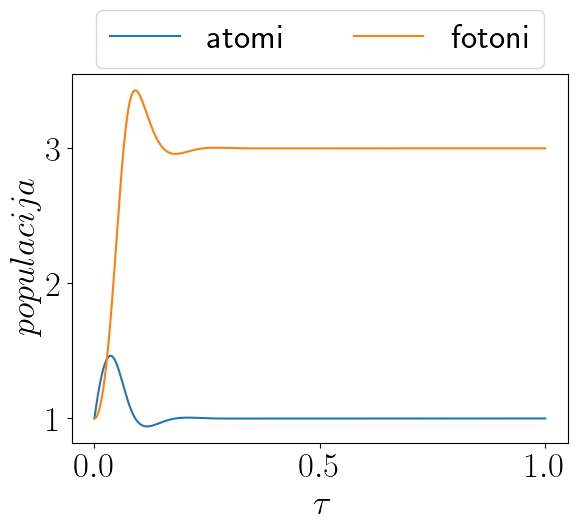

<Figure size 700x500 with 0 Axes>

In [3]:
initial_conditions = [1, 1]
x_values = np.linspace(0, 25, 1000)
p = 0.5
r = 2

result = odeint(laser, initial_conditions, x_values, args=(p,r))
A_solution, F_solution = result.T
X = [i / x_values[-1] for i in x_values] #normiran čas

A, F = zamenjava([A_solution, F_solution])
df = pd.DataFrame({
    'atomi': A,
    'fotoni' : F,
}, index=X)
#ax = df.plot.area(figsize=(10,7))
ax = plt.subplot()
plt.figure(figsize=(7,5))
#ax.plot(df['atomi'], df['fotoni'])
ax.plot(X, df['atomi'], label='atomi')
ax.plot(X, df['fotoni'], label='fotoni')
ax.set_xlabel('$\\tau$')
ax.set_ylabel('$populacija$')
ax.legend(bbox_to_anchor=(0.5, 1.22), loc='upper center', ncol=5)
#ax.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
#plt.savefig('slike/zajci_lisice.pdf')
plt.show()

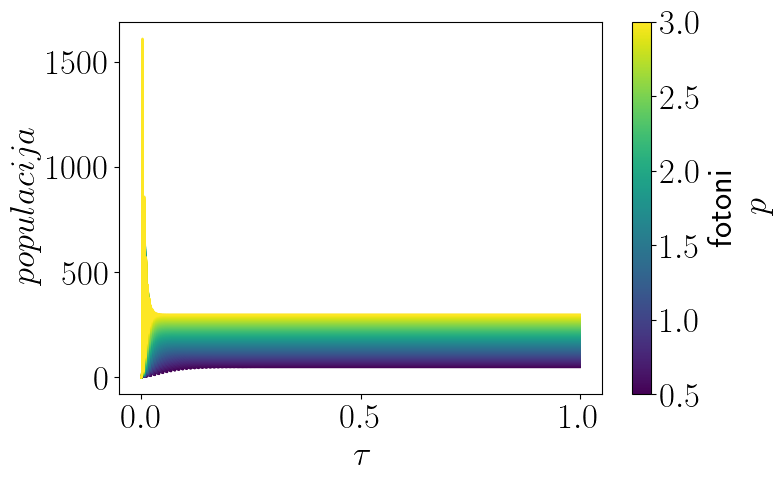

In [4]:
initial_conditions = [1, 1]
x_values = np.linspace(0, 100, 10000)
X = [i / x_values[-1] for i in x_values] #normiran čas
p_variacije = np.linspace(0.5, 3, 150)
p=0.01
r=0.4

fotoni = []
atomi = []
for i in p_variacije:
    result = odeint(laser, initial_conditions, x_values, args=(p,i))
    A_solution, F_solution = result.T
    A, F = zamenjava([A_solution, F_solution])
    fotoni.append(F)
    atomi.append(A)
fig, ax = plt.subplots(figsize=(8,5))
cmap_z = plt.get_cmap('viridis')
cmap_l = plt.get_cmap('autumn')
for i in range(len(p_variacije)):
    color = cmap_z(i / (len(p_variacije) - 1))
    ax.plot(X, fotoni[i], color=color)
    color = cmap_l(i / (len(p_variacije) - 1))
    #ax.plot(X, atomi[i], color=color)
sm_z = mpl.cm.ScalarMappable(cmap=cmap_z)
sm_z.set_array(p_variacije)
cbar_z = plt.colorbar(sm_z, ax=ax)
cbar_z.set_label('fotoni \n $p$')
sm_l = mpl.cm.ScalarMappable(cmap=cmap_l)
sm_l.set_array(p_variacije)
#cbar_l = plt.colorbar(sm_l, ax=ax)
#cbar_l.set_label('atomi')
plt.tight_layout()
plt.xlabel('$\\tau$')
plt.ylabel('$populacija$')
#plt.savefig('slike/fotoni_atomi_r0.4.pdf')
plt.show()

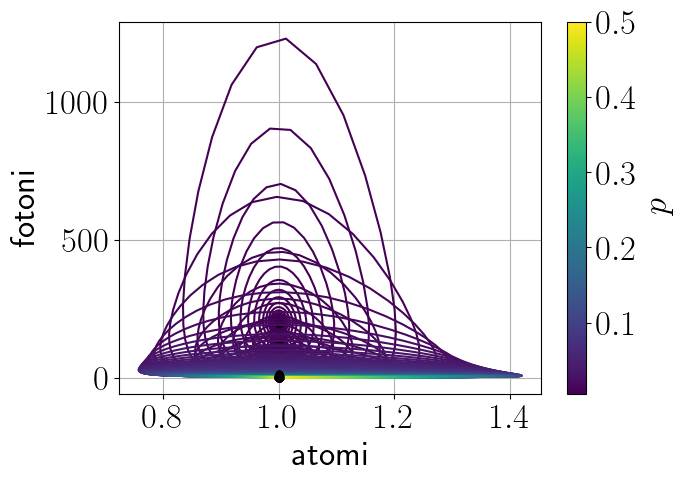

In [5]:
initial_conditions = [1, 1]
x_values = np.linspace(0, 100, 10000)
X = [i / x_values[-1] for i in x_values] #normiran čas
p_variacije = np.linspace(0.005, 0.5, 150)
p=1
r=1

fotoni_ = []
atomi_ = []
for i in p_variacije:
    result = odeint(laser, initial_conditions, x_values, args=(i,r))
    A_solution, F_solution = result.T
    #A, F = zamenjava([A_solution, F_solution])
    A,F = (A_solution,F_solution)
    fotoni_.append(F)
    atomi_.append(A)
fig, ax = plt.subplots(figsize=(7,5))
cmap_z = plt.get_cmap('viridis')
for i in range(len(p_variacije)):
    color = cmap_z(i / (len(p_variacije) - 1))
    ax.plot(atomi_[i], fotoni_[i], color=color)
    p = p_variacije[i]
    #ax.plot([r/p], [0], 'ko')
    ax.plot([1], [r/p-1], 'ko')
sm_z = mpl.cm.ScalarMappable(cmap=cmap_z)
sm_z.set_array(p_variacije)
cbar_z = plt.colorbar(sm_z, ax=ax)
cbar_z.set_label('$p$')
plt.tight_layout()
plt.xlabel('atomi')
plt.ylabel('fotoni')
plt.grid()
#plt.savefig('slike/fotoni_atomi_fazni_visoki_p.pdf')
plt.show()

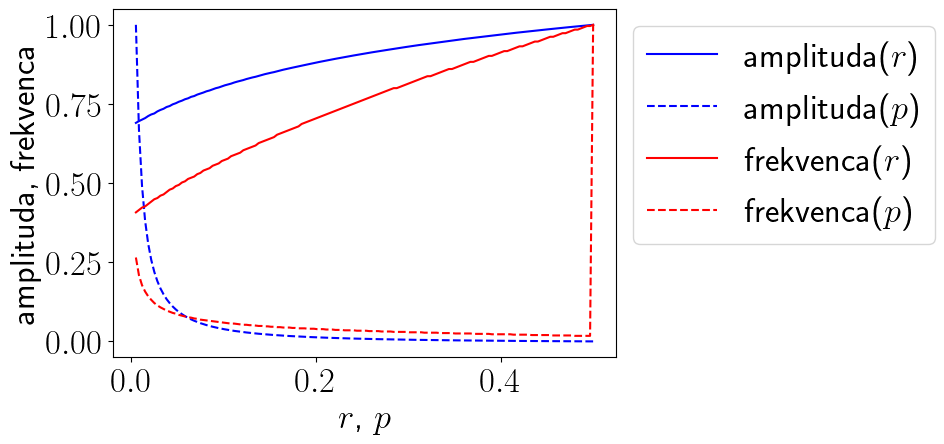

In [20]:
amplituda = []
frekvenca = []
amplituda_ = []
frekvenca_ = []
for i in range(len(fotoni)):
    spectrum = np.fft.fft(fotoni[i])
    frequencies = np.fft.fftfreq(len(spectrum))
    dominant_frequency = np.abs(frequencies[1:][np.argmax(np.abs(spectrum[1:]))])
    ampl = np.abs(spectrum)[np.where(frequencies==dominant_frequency)]
    amplituda.append(ampl)
    frekvenca.append(dominant_frequency)

    spectrum = np.fft.fft(fotoni_[i])
    frequencies = np.fft.fftfreq(len(spectrum))
    dominant_frequency = np.abs(frequencies[1:][np.argmax(np.abs(spectrum[1:]))])
    ampl = np.abs(spectrum)[np.where(frequencies==dominant_frequency)]
    amplituda_.append(ampl)
    frekvenca_.append(dominant_frequency)
plt.figure(figsize=(10,5))
plt.plot(p_variacije, amplituda/max(amplituda), 'b-', label='amplituda($r$)')
plt.plot(p_variacije, amplituda_/max(amplituda_), 'b--', label='amplituda($p$)')
plt.plot(p_variacije, frekvenca/max(frekvenca), 'r-', label='frekvenca($r$)')
plt.plot(p_variacije, frekvenca_/max(frekvenca_), 'r--', label='frekvenca($p$)')
plt.xlabel('$r$, $p$')
plt.ylabel('amplituda, frekvenca')
plt.legend(bbox_to_anchor=(1, 1), ncol=1)
plt.tight_layout()
#plt.savefig('slike/amplituda_frek.pdf')
plt.show()